In [1]:
!pip install torchsummary torchvision

In [2]:
import time

from collections import OrderedDict
from typing import List, Tuple

import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
import pandas as pd
import torch
import torch.optim as optim
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, random_split

from torchsummary import summary
from torchvision import models

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, confusion_matrix

import flwr
from flwr.client import Client, NumPyClient
from flwr.server import ServerConfig
from flwr.common import Metrics
from flwr.server.strategy import FedAvg
from flwr.simulation import start_simulation

DEVICE = torch.device("cpu")  # Try "cuda" to train on GPU
print(f"Training on {DEVICE}")
print(f"Flower {flwr.__version__} / PyTorch {torch.__version__}")

Training on cpu
Flower 1.7.0 / PyTorch 2.2.1+cu121


In [3]:
# Define the path to the dataset and the sequence length
PATH = '../datasets/WISDM_ar_v1.1_balanced.csv'
NUM_CLIENTS_TRAIN = 27
NUM_CLIENTS_TEST = 9
NUM_CLASSES = 4
LEARNING_RATE=5e-4
NUM_ROUNDS = 50
NUM_EPOCHS = 25
SEQUENCE_LENGTH = 128
STRIDE = 64
BATCH_SIZE = 64
PATIENCE = 0

PREPROCESS_PLOTS = False

BACKEND_CONFIG = {"client_resources": {"num_cpus": 1, "num_gpus": 0.0}}
if DEVICE.type == "cpu":
    BACKEND_CONFIG = {"client_resources": {"num_cpus": 1, "num_gpus": 1.0}}

In [4]:
x_axis = 'x'
y_axis = 'y'
z_axis = 'z'
THRESHOLDS = [
    1.0000, 
    0.0187, 
    0.0113, 
    1.0000
]  # List of thresholds

In [5]:
def recurrence_plot_vector(data, eps):
    """
    Generate a recurrence plot for a vector sequence using a specified threshold.
    
    Parameters:
    - data: torch.Tensor, shape (N, D), where N is the number of vectors and D is their dimensionality.
    - eps: float, the threshold for recurrence.

    Returns:
    - recurrence_matrix: torch.Tensor, shape (N, N), binary recurrence matrix.
    """
    # Ensure the input is a tensor on the correct device
    if not isinstance(data, torch.Tensor):
        raise ValueError("Input data must be a PyTorch tensor.")
    
    # Compute pairwise Euclidean distances using PyTorch broadcasting
    data = data.to(torch.float32)  # Ensure correct dtype for computation
    distances = torch.cdist(data, data, p=2)  # Compute pairwise distances

    # Apply the threshold
    recurrence_matrix = (distances <= eps).int()

    return recurrence_matrix


In [6]:
def preprocess_and_save_recurrence_plots(df, thresholds, sequence_length=50, stride=1, save_path="processed_data.pt"):
    """
    Preprocess the dataset to generate recurrence plots and save them.

    Parameters:
    - df: DataFrame containing the data.
    - thresholds: list of floats, thresholds for recurrence plots.
    - sequence_length: int, length of each sequence.
    - stride: int, step size between sequences.
    - save_path: str, path to save the preprocessed data.

    Returns:
    - None
    """
    try:
        processed_data = []
        labels = []

        for idx in range(0, len(df) - sequence_length + 1, stride):
            # Select a window of data points
            window = df.iloc[idx:idx + sequence_length]

            # Extract x, y, z values
            sequence = torch.tensor(window[['x', 'y', 'z']].values, dtype=torch.float32)

            # Generate multi-channel recurrence plots
            recurrence_plots = torch.stack(
                [recurrence_plot_vector(sequence, threshold) for threshold in thresholds], dim=-1
            )

            # The label is the activity of the last element in the sequence
            label = int(window.iloc[-1]['activity'])

            processed_data.append(recurrence_plots)
            labels.append(label)

        # Convert to tensors
        processed_data = torch.stack(processed_data)  # Shape: (num_sequences, sequence_length, sequence_length, num_channels)
        labels = torch.tensor(labels, dtype=torch.long)  # Shape: (num_sequences,)

        # Save to disk
        torch.save({'data': processed_data, 'labels': labels}, save_path)
        print(f"Preprocessed data saved to {save_path}")

    except Exception as e:
        print(f"An error occurred during preprocessing: {e}")


In [7]:
# Load data from file
df = pd.read_csv(PATH, header=None, names=['user_id', 'activity', 'timestamp', 'x', 'y', 'z'])
if(NUM_CLASSES == 4):
    # Filter for specific activities
    df = df.loc[
        (df['activity'] == 'Walking') | 
        (df['activity'] == 'Jogging') | 
        (df['activity'] == 'Sitting') | 
        (df['activity'] == 'Standing') 
    ].reset_index(drop=True)
    
# Map activities to integers if not already done
activity_mapping = {activity: idx for idx, activity in enumerate(df['activity'].unique())}
df['activity'] = df['activity'].map(activity_mapping)

# Split the dataset by user_id
user_ids = df['user_id'].unique()
user_ids

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36])

In [8]:
# Preprocess and save for each user
if(PREPROCESS_PLOTS):
    for user_id in df['user_id'].unique():
        user_df = df[df['user_id'] == user_id]
        preprocess_and_save_recurrence_plots(
            user_df,
            thresholds=THRESHOLDS,
            sequence_length=SEQUENCE_LENGTH,
            stride=STRIDE,
            save_path=f"processed_user_{user_id}.pt"
        )


In [9]:
class WISDMDataset(Dataset):
    def __init__(self, processed_data_path):
        """
        Initialize the dataset with precomputed recurrence plots.

        Parameters:
        - processed_data_path: str, path to the preprocessed data file.
        """
        # Load the preprocessed data
        data = torch.load(processed_data_path)
        self.data = data['data'].float().permute(0, 3, 1, 2)
        self.labels = data['labels'].long()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {'data': self.data[idx], 'label': self.labels[idx]}


In [10]:
def load_client_data(partition_id: int, batch_size=32, split=True):
    try:
        if not isinstance(partition_id, int):  # Ensure partition ID is an integer
            partition_id = int(partition_id)

        # Load preprocessed data for this client
        processed_data_path = f"processed_user_{partition_id}.pt"
        dataset = WISDMDataset(processed_data_path)

        if(not split):
            return DataLoader(dataset, batch_size=batch_size, shuffle=True), None
            
        # Split the dataset into train and validation sets (80% train, 20% validation)
        train_size = int(0.8 * len(dataset))
        val_size = len(dataset) - train_size
        train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

        # Create DataLoader objects
        trainloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        valloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

        return trainloader, valloader
    except Exception as e:
        print(f"An error occurred (load_client_data): {e}")
        return None, None


In [11]:
#for i in range(1,25):
train_loader, val_loader = load_client_data(partition_id=8)
batch = next(iter(train_loader))
data, labels = batch["data"], batch["label"]
x_shape = data.shape
y_shape = labels.shape
x_shape, y_shape

(torch.Size([32, 4, 128, 128]), torch.Size([32]))

In [12]:
def load_test_data():
    """
    Load test data from preprocessed recurrence plot files.

    Returns:
    - testloader: DataLoader for the test data.
    """
    try:
        test_clients = user_ids[-NUM_CLIENTS_TEST:]
        print(f"Test clients: {test_clients}")
        
        datasets = []

        for client_id in test_clients:
            # Construct the file path for the preprocessed data
            file_path = f"processed_user_{client_id}.pt"
            try:
                # Create a dataset object for the client's preprocessed data
                dataset = WISDMDataset(processed_data_path=file_path)
                datasets.append(dataset)
            except FileNotFoundError:
                print(f"Preprocessed file not found for client {client_id}: {file_path}")
                continue

        if not datasets:
            raise ValueError("No preprocessed data found for any test client.")

        # Concatenate all client datasets into one
        combined_dataset = torch.utils.data.ConcatDataset(datasets)

        # Create DataLoader
        testloader = DataLoader(combined_dataset, batch_size=BATCH_SIZE, shuffle=False)

        return testloader

    except Exception as e:
        print(f"An error occurred in load_test_data: {e}")
        return None


In [13]:
test_loader = load_test_data()
batch = next(iter(test_loader))
data, labels = batch["data"], batch["label"]
x_shape = data.shape
y_shape = labels.shape
x_shape, y_shape

Test clients: [28 29 30 31 32 33 34 35 36]


(torch.Size([64, 4, 128, 128]), torch.Size([64]))

In [14]:
class ModifiedMobileNetV2(nn.Module):
    def __init__(self, num_classes):
        super(ModifiedMobileNetV2, self).__init__()
        # Load MobileNetV2 with pretrained weights
        self.base_model = models.mobilenet_v2(weights=None)
        self.base_model.load_state_dict(torch.load("mobilenet_v2-b0353104.pth"))
        
        # Modify the input layer to handle 4 channels instead of 3
        self.base_model.features[0][0] = nn.Conv2d(
            in_channels=num_classes, out_channels=32, kernel_size=3, stride=2, padding=1, bias=False
        )
        
        # Replace the final layer to match the number of classes
        self.base_model.classifier[1] = nn.Linear(self.base_model.last_channel, num_classes)
        
    def forward(self, x):
        return self.base_model(x)

In [15]:
def test(net, testloader):
    """Evaluate the PEN network on the entire test set and return various metrics."""
    try:
        criterion = torch.nn.CrossEntropyLoss()
        correct, total, loss = 0, 0, 0.0
        net.eval()
        
        all_labels = []
        all_predictions = []

        with torch.no_grad():
            for batch in testloader:
                data, labels = batch["data"].to(DEVICE), batch["label"].to(DEVICE)
                outputs = net(data)

                loss += criterion(outputs, labels).item()
                _, predicted = torch.max(outputs.data, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())

        # Calculate metrics
        loss /= len(testloader.dataset)
        balanced_acc = balanced_accuracy_score(all_labels, all_predictions)
        f1 = f1_score(all_labels, all_predictions, average='weighted')
        precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
        conf_matrix = confusion_matrix(all_labels, all_predictions, normalize='true').round(2)

        return loss, balanced_acc, f1, precision, conf_matrix

    except Exception as e:
        print(f"An error occurred (test): {e}")
        return None, None, None, None, None


In [16]:
def train(net, trainloader, epochs: int, verbose=False):
    """
    Train the model with early stopping and evaluate it at each epoch.

    Parameters:
    - net: PyTorch model to be trained.
    - trainloader: DataLoader object containing the training data.
    - epochs: Number of epochs to train the model.
    - criterion: Loss function. If None, defaults to CrossEntropyLoss.
    - optimizer: Optimization algorithm. If None, defaults to Adam optimizer.
    - verbose: Boolean indicating whether to print detailed information during training.

    Returns:
    - train_loss: List of training losses for each epoch.
    """
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(net.parameters())
    
    net.train()
    train_losses = []

    for epoch in range(epochs):
        correct, total, epoch_loss = 0, 0, 0.0
        start_epoch_time = time.time()

        for batch in trainloader:
            data, labels = batch["data"].to(DEVICE), batch["label"].to(DEVICE)
            optimizer.zero_grad()
            outputs = net(data)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            total += labels.size(0)
            correct += (torch.max(outputs.data, 1)[1] == labels).sum().item()

        avg_loss = epoch_loss / len(trainloader)
        train_losses.append(avg_loss)

        end_epoch_time = time.time()
        epoch_time = end_epoch_time - start_epoch_time

        if verbose:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}, Time: {epoch_time:.2f} seconds')

    return train_losses

In [17]:
def freeze_layers(model, unfrozen_layers):
    frozen = 0
    
    # Freeze all layers in the model initially
    for param in model.base_model.parameters():
        param.requires_grad = False
    
    # Unfreeze only the classifier layer parameters
    for param in reversed(list(model.base_model.classifier.parameters())):
        if(frozen < unfrozen_layers):
            param.requires_grad = True
            frozen += 1
    
    # Unfreeze only the classifier layer parameters
    for param in reversed(list(model.base_model.features.parameters())):
            if(frozen < unfrozen_layers):
                param.requires_grad = True
                frozen += 1
    

In [18]:
model = ModifiedMobileNetV2(NUM_CLASSES).to(DEVICE)
UNFROZEN_LAYERS = len(list(model.base_model.parameters())) * 0.5
freeze_layers(model, UNFROZEN_LAYERS)


In [19]:
summary(model, (NUM_CLASSES, 40, 40), device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 20, 20]           1,152
       BatchNorm2d-2           [-1, 32, 20, 20]              64
             ReLU6-3           [-1, 32, 20, 20]               0
            Conv2d-4           [-1, 32, 20, 20]             288
       BatchNorm2d-5           [-1, 32, 20, 20]              64
             ReLU6-6           [-1, 32, 20, 20]               0
            Conv2d-7           [-1, 16, 20, 20]             512
       BatchNorm2d-8           [-1, 16, 20, 20]              32
  InvertedResidual-9           [-1, 16, 20, 20]               0
           Conv2d-10           [-1, 96, 20, 20]           1,536
      BatchNorm2d-11           [-1, 96, 20, 20]             192
            ReLU6-12           [-1, 96, 20, 20]               0
           Conv2d-13           [-1, 96, 10, 10]             864
      BatchNorm2d-14           [-1, 96,

In [20]:
train_losses = train(
    net=model,
    trainloader=train_loader,
    epochs=NUM_EPOCHS,
    verbose=True
)

print("Training complete.")

Epoch [1/25], Loss: 0.8653, Time: 13.89 seconds
Epoch [2/25], Loss: 0.4332, Time: 7.81 seconds
Epoch [3/25], Loss: 0.3197, Time: 4.90 seconds
Epoch [4/25], Loss: 0.3224, Time: 4.30 seconds
Epoch [5/25], Loss: 0.0991, Time: 4.99 seconds
Epoch [6/25], Loss: 0.2881, Time: 4.60 seconds
Epoch [7/25], Loss: 0.2969, Time: 4.51 seconds
Epoch [8/25], Loss: 0.2324, Time: 4.79 seconds
Epoch [9/25], Loss: 0.0862, Time: 4.31 seconds
Epoch [10/25], Loss: 0.0441, Time: 4.21 seconds
Epoch [11/25], Loss: 0.1025, Time: 4.49 seconds
Epoch [12/25], Loss: 0.0763, Time: 4.51 seconds
Epoch [13/25], Loss: 0.2707, Time: 4.50 seconds
Epoch [14/25], Loss: 0.1285, Time: 4.70 seconds
Epoch [15/25], Loss: 0.1637, Time: 5.20 seconds
Epoch [16/25], Loss: 0.0305, Time: 5.08 seconds
Epoch [17/25], Loss: 0.0731, Time: 5.50 seconds
Epoch [18/25], Loss: 0.0413, Time: 4.51 seconds
Epoch [19/25], Loss: 0.0251, Time: 4.29 seconds
Epoch [20/25], Loss: 0.0230, Time: 4.40 seconds
Epoch [21/25], Loss: 0.0225, Time: 4.60 seconds


In [21]:
_, balanced_acc, precision, f1, conf_matrix = test(model, val_loader)
print(f"  Balanced Accuracy: {balanced_acc:.4f}")
print(f"  Precision: {precision:.4f}")
print(f"  F1 Score: {f1:.4f}")
print(f"  Confusion Matrix: \n{conf_matrix.round(2)}")

  Balanced Accuracy: 0.7500
  Precision: 0.7679
  F1 Score: 0.8429
  Confusion Matrix: 
[[0.33 0.67 0.   0.  ]
 [0.   1.   0.   0.  ]
 [0.   0.   0.75 0.25]
 [0.   0.   0.08 0.92]]


In [22]:
_, balanced_acc, precision, f1, conf_matrix = test(model, test_loader)
print(f"  Balanced Accuracy: {balanced_acc:.4f}")
print(f"  Precision: {precision:.4f}")
print(f"  F1 Score: {f1:.4f}")
print(f"  Confusion Matrix: \n{conf_matrix.round(2)}")

  Balanced Accuracy: 0.7384
  Precision: 0.7252
  F1 Score: 0.7502
  Confusion Matrix: 
[[0.66 0.33 0.01 0.01]
 [0.03 0.94 0.03 0.  ]
 [0.   0.02 0.73 0.25]
 [0.01 0.11 0.25 0.63]]


In [23]:
def set_parameters(net, parameters: List[np.ndarray]):
    try:
        params_dict = zip(net.state_dict().keys(), parameters)
        state_dict = OrderedDict({k: torch.from_numpy(np.copy(v)) for k, v in params_dict})
        net.load_state_dict(state_dict, strict=True)
    except Exception as e:
        print(f"An error occurred (set_parameters): {e}")


def get_parameters(net) -> List[np.ndarray]:
    try:
        return [val.cpu().numpy() for _, val in net.state_dict().items()]
    except Exception as e:
        print(f"An error occurred (get_parameters): {e}")
        return None

In [24]:
class FlowerClient(NumPyClient):
    def __init__(self, net, trainloader, valloader):
        self.net = net
        self.trainloader = trainloader
        self.valloader = valloader

    def get_parameters(self, config):
        return get_parameters(self.net)

    def fit(self, parameters, config):
        set_parameters(self.net, parameters)
        train_losses = train(
            net=self.net,
            trainloader=self.trainloader,
            epochs=NUM_EPOCHS,
            verbose=False
        )
        return get_parameters(self.net), len(self.trainloader), {}

    def evaluate(self, parameters, config):
        set_parameters(self.net, parameters)

        # If valloader and trainloader are the same, then this client will
        # be tested with the global test dataset
        if(self.valloader == self.trainloader):
            loss, balanced_acc, f1, precision, conf_matrix = test(self.net, test_loader)
        else:
            loss, balanced_acc, f1, precision, conf_matrix = test(self.net, self.valloader)
            
        return float(loss), len(self.valloader), {"accuracy": float(balanced_acc), "f1score": float(f1), "precision": float(precision)}

In [25]:
def client_fn(context) -> Client:
    """Create a Flower client representing a single organization."""
    try:
        # Load model
        net = ModifiedMobileNetV2(NUM_CLASSES).to(DEVICE)
        freeze_layers(net, UNFROZEN_LAYERS)
        
        partition_id = int(context)
        client_id = int(partition_id) + 1

        # Split = False doesn't create a validation dataset from this client
        # Then all data is used to train
        trainloader, valloader = load_client_data(partition_id=client_id, split=False)

        # If valloader is None, then this client will not use
        # it to test its local model. It will use the global test dataset
        if(valloader == None):
            valloader = trainloader
        
        return FlowerClient(net, trainloader, trainloader).to_client()
    except Exception as e:
        print(f"An error occurred (client_fn): {e}")
        return None

In [26]:
def weighted_average(metrics: List[Tuple[int, Metrics]]) -> Metrics:
    try:
        # Multiply accuracy of each client by number of examples used
        accuracies = [num_examples * m["accuracy"] for num_examples, m in metrics]
        f1s = [num_examples * m["f1score"] for num_examples, m in metrics]
        precisions = [num_examples * m["precision"] for num_examples, m in metrics]
        examples = [num_examples for num_examples, _ in metrics]

        # Aggregate and return custom metric (weighted average)
        return {"accuracy": sum(accuracies) / sum(examples), "f1score": sum(f1s) / sum(examples), "precision": sum(precisions) / sum(examples)}
    except Exception as e:
        print(f"An error occurred (weighted_average): {e}")
        return None

In [27]:
def server_evaluate_fn(server_round:int, parameters, config):
    try:
        # Load model
        model = ModifiedMobileNetV2(NUM_CLASSES).to(DEVICE)
        freeze_layers(model, UNFROZEN_LAYERS)

        params_dict = zip(model.state_dict().keys(), parameters)
        state_dict = OrderedDict({k: torch.from_numpy(np.copy(v)) for k, v in params_dict})
        model.load_state_dict(state_dict, strict=True)
        
        loss, balanced_acc, f1, precision, conf_matrix = test(model, test_loader)

        return float(loss), {"accuracy": float(balanced_acc), "f1score": float(f1), "precision": float(precision)}
    except Exception as e:
        print(f"An error occurred (server_evaluate_fn): {e}")
        return None, None


In [28]:
# Create FedAvg strategy
strategy = FedAvg(
    fraction_fit=0.8,  # Sample % of available clients for training
    fraction_evaluate=0.2,  # Sample % of available clients for evaluation
    min_fit_clients=1,  # sample  clients for training
    min_evaluate_clients=1,  # sample clients for evaluation
    min_available_clients=1,  # Wait until all clients are available
    evaluate_metrics_aggregation_fn=weighted_average,
    evaluate_fn=server_evaluate_fn,
)

# Configure the server for 5 rounds of training
config = ServerConfig(num_rounds=NUM_ROUNDS)


hist = start_simulation(
    num_clients=NUM_CLIENTS_TRAIN,
    client_fn=client_fn,
    strategy=strategy,
    config=config,
    client_resources={'num_cpus': 16, 'num_gpus': 0.0}
)

INFO flwr 2024-11-29 23:02:38,359 | app.py:178 | Starting Flower simulation, config: ServerConfig(num_rounds=50, round_timeout=None)
2024-11-29 23:02:40,900	INFO worker.py:1621 -- Started a local Ray instance.
INFO flwr 2024-11-29 23:02:41,823 | app.py:213 | Flower VCE: Ray initialized with resources: {'accelerator_type:A100': 1.0, 'GPU': 1.0, 'node:__internal_head__': 1.0, 'object_store_memory': 19456180224.0, 'node:10.233.68.238': 1.0, 'memory': 38912360448.0, 'CPU': 32.0}
INFO flwr 2024-11-29 23:02:41,824 | app.py:219 | Optimize your simulation with Flower VCE: https://flower.dev/docs/framework/how-to-run-simulations.html
INFO flwr 2024-11-29 23:02:41,825 | app.py:242 | Flower VCE: Resources for each Virtual Client: {'num_cpus': 16, 'num_gpus': 0.0}
INFO flwr 2024-11-29 23:02:41,833 | app.py:288 | Flower VCE: Creating VirtualClientEngineActorPool with 2 actors
INFO flwr 2024-11-29 23:02:41,834 | server.py:89 | Initializing global parameters
INFO flwr 2024-11-29 23:02:41,834 | server

In [29]:
def plot_metrics_by_round(data, metric, legend, is_loss=False):
    df = pd.DataFrame(data, columns=["Round", "Accuracy"])
    # Set the style
    # Set the style
    sns.set_theme(style="dark")

    # Create the line plot with customizations
    plt.figure(figsize=(10, 6))
    sns.lineplot(x="Round", y="Accuracy", data=df, marker="o", color="royalblue", linewidth=2.5)

    # Customize the title and labels
    plt.title(f"{metric} per Round ({legend})", fontsize=16, fontweight='bold')
    plt.xlabel("Round", fontsize=14)
    plt.ylabel(metric, fontsize=14)

    # Customize the grid
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)

    # Customize the ticks
    plt.xticks(ticks=df["Round"], fontsize=12)  # Ensure only integer rounds are shown on x-axis
    plt.yticks(fontsize=12)

    # Add a range for the y-axis for better visibility
    if(not is_loss):
        plt.ylim(0, 1)

    # Display the plot
    plt.show()

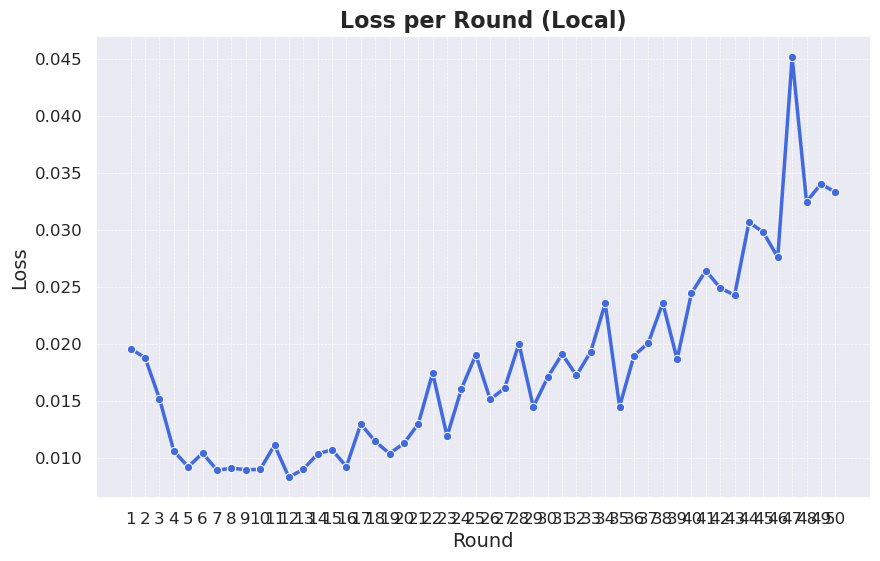

In [30]:
plot_metrics_by_round(hist.losses_distributed, 'Loss', 'Local', True)

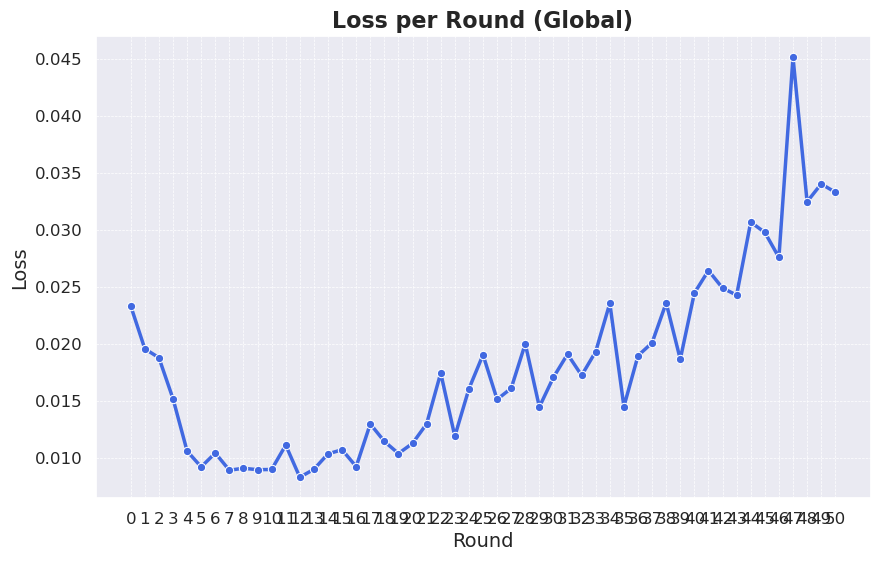

In [31]:
plot_metrics_by_round(hist.losses_centralized, 'Loss', 'Global', True)

In [32]:
def plot_multiple_metrics_by_round(data1, data2, data3, legend):
    # Convert data to DataFrames
    df1 = pd.DataFrame(data1, columns=["Round", "Metric"])
    df2 = pd.DataFrame(data2, columns=["Round", "Metric"])
    df3 = pd.DataFrame(data3, columns=["Round", "Metric"])
    
    # Set the style
    sns.set_theme(style="dark")
    
    # Create the main plot
    plt.figure(figsize=(10, 6))
    
    # Plot each metric with different styles
    sns.lineplot(x="Round", y="Metric", data=df1, marker="o", color="royalblue", linewidth=2.5, label="Accuracy")
    sns.lineplot(x="Round", y="Metric", data=df2, marker="s", color="forestgreen", linewidth=2.5, label="F1 Score")
    sns.lineplot(x="Round", y="Metric", data=df3, marker="^", color="darkorange", linewidth=2.5, label="Precision")
    
    # Customize the title and labels
    plt.title(f"Metrics per Round ({legend})", fontsize=16, fontweight='bold')
    plt.xlabel("Round", fontsize=14)
    plt.ylabel("Value", fontsize=14)
    
    # Customize the grid
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    
    # Calculate and set x-axis ticks
    round_ticks = range(0, max(df1["Round"].max(), df2["Round"].max(), df3["Round"].max()) + 10, 10)
    plt.xticks(ticks=round_ticks, fontsize=12)  # Ensure only integer rounds are shown on x-axis
    
    # Customize the y-axis ticks
    plt.yticks(fontsize=12)
    
    # Set y-axis limits
    plt.ylim(0.2, 1.0)
    
    # Add a legend
    plt.legend(title="Metrics", title_fontsize='13', fontsize='12')
    
    # Inset plot for the last 5 values
    inset_axes = plt.gca().inset_axes([0.6, 0.1, 0.35, 0.35])  # Position inset: [left, bottom, width, height]
    sns.lineplot(x="Round", y="Metric", data=df1.tail(5), marker="o", color="royalblue", linewidth=2.0, ax=inset_axes)
    sns.lineplot(x="Round", y="Metric", data=df2.tail(5), marker="s", color="forestgreen", linewidth=2.0, ax=inset_axes)
    sns.lineplot(x="Round", y="Metric", data=df3.tail(5), marker="^", color="darkorange", linewidth=2.0, ax=inset_axes)
    
    # Annotate the last point in the inset
    for df, color in zip([df1, df2, df3], ["royalblue", "forestgreen", "darkorange"]):
        last_point = df.tail(5).iloc[-1]
        inset_axes.text(last_point["Round"], last_point["Metric"]*0.985, 
                        f"{last_point['Metric']:.2f}", 
                        fontsize=10, fontweight='bold', color=color,
                        ha='right', va='bottom')
    
    # Customize the inset plot
    inset_axes.set_xlim(df1["Round"].max() - 4, df1["Round"].max())  # Set x-axis range for last 5 rounds
    #inset_axes.set_ylim(0.2, 1.0)  # Match y-axis limits to the main plot
    inset_axes.set_title("Last 5 Rounds", fontsize=12)
    inset_axes.set_ylabel("Value")
    inset_axes.grid(True, which='both', linestyle='--', linewidth=0.5)
    
    # Display the plot
    plt.show()

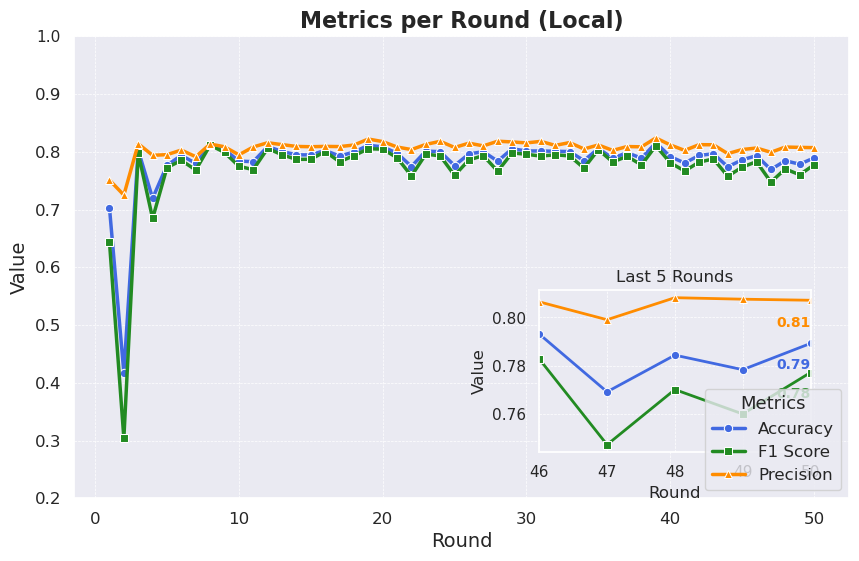

In [33]:
plot_multiple_metrics_by_round(hist.metrics_distributed['accuracy'], hist.metrics_distributed['f1score'], hist.metrics_distributed['precision'], 'Local')

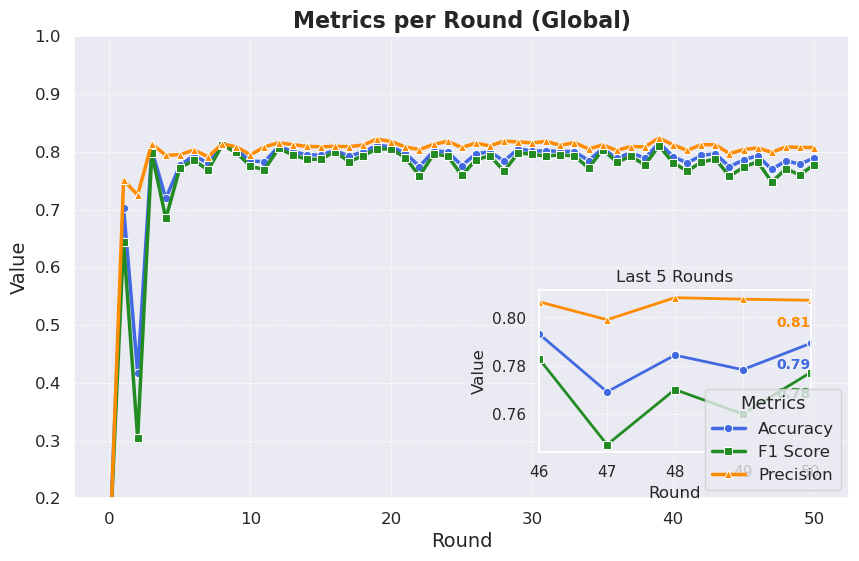

In [34]:
plot_multiple_metrics_by_round(hist.metrics_centralized['accuracy'], hist.metrics_centralized['f1score'], hist.metrics_centralized['precision'], 'Global')

In [35]:
from datetime import datetime
import os
import json

# Define the folder structure and ensure it exists
SAVE_FOLDER = "./results/federated"
os.makedirs(SAVE_FOLDER, exist_ok=True)  # Create folder if it doesn't exist

# Function to manually serialize the flwr.server.History object
def serialize_history(hist):
    # Prepare a dictionary to hold the serialized data
    serialized_data = {}

    # Serialize loss data
    serialized_data['loss'] = {
        'distributed': [v for k, v in hist.losses_distributed],
        'centralized': [v for k, v in hist.losses_centralized]
    }

    # Serialize metrics data
    serialized_data['metrics'] = {
        'distributed': {
            'accuracy': [v for k, v in hist.metrics_distributed['accuracy']],
            'f1score': [v for k, v in hist.metrics_distributed['f1score']],
            'precision': [v for k, v in hist.metrics_distributed['precision']]
        },
        'centralized': {
            'accuracy': [v for k, v in hist.metrics_centralized['accuracy']],
            'f1score': [v for k, v in hist.metrics_centralized['f1score']],
            'precision': [v for k, v in hist.metrics_centralized['precision']]
        }
    }

    # Return the dictionary instead of converting it to JSON here
    return serialized_data

# Save the serialized history to a JSON file
def save_history_as_json(hist):
    # Generate a filename with the given format
    datetime_str = datetime.now().strftime("%Y%m%d_%H%M%S")
    filename = f"{SAVE_FOLDER}/recurrence_mobilenet_wisdm_{datetime_str}.json"
    
    # Serialize the history object
    serialized_hist = serialize_history(hist)
    
    # Save to JSON
    with open(filename, "w") as f:
        # Dump the dictionary directly to the JSON file
        json.dump(serialized_hist, f, indent=4)
    
    print(f"History saved to {filename}")

# Example to call the save function
save_history_as_json(hist) # Ensure hist is a valid object you want to serialize.


History saved to ./results/federated/recurrence_mobilenet_wisdm_20241130_004603.json
